In [1]:
# Install Prophet
import sys
!{sys.executable} -m pip install prophet

# Import necessary libraries for Baseline, ARIMA/SARIMA, and Prophet modeling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Load the engineered dataset from Notebook 2
master_df = pd.read_csv('master_engineered_sales.csv')

# Ensure 'date' column is datetime and sorted
master_df['date'] = pd.to_datetime(master_df['date'])
master_df = master_df.sort_values(by=['store_id', 'department', 'date']).reset_index(drop=True)

print("Dataset loaded successfully (Baseline, ARIMA/SARIMA & Prophet)!")
print(f"Dataset Shape: {master_df.shape}")
display(master_df.head(2))

Defaulting to user installation because normal site-packages is not writeable
Dataset loaded successfully (Baseline, ARIMA/SARIMA & Prophet)!
Dataset Shape: (152000, 26)


,store_id,department,date,weekly_sales,is_holiday,store_size,temperature,fuel_price,markdown_1,markdown_2,...,sales_lag_4,sales_rolling_mean_4,season_Spring,season_Summer,season_Winter,store_type_B,store_type_C,region_North,region_South,region_West
0,1,1,2022-01-29,15166.69,0,213810,78.37,4.41,4436.06,1416.64,...,119075.96,53675.7850,False,False,True,False,False,True,False,False
1,1,1,2022-02-05,15601.13,0,213810,59.50,4.07,2137.71,76.26,...,35525.05,27698.4675,False,False,True,False,False,True,False,False


In [2]:
# Select a sample store and department for Modeling (e.g., store_id = 1, department = 1)
store_id = 1
dept_id = 1

df_sample = master_df[(master_df['store_id'] == store_id) & (master_df['department'] == dept_id)].copy()

# Sort by date to ensure chronological order
df_sample = df_sample.sort_values('date').reset_index(drop=True)

# Split into Train and Test sets (e.g., last 12 weeks for testing)
train_df = df_sample.iloc[:-12]
test_df = df_sample.iloc[-12:]

print(f"Sample Store {store_id}, Dept {dept_id}")
print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")

Sample Store 1, Dept 1
Training set shape: (140, 26)
Testing set shape: (12, 26)


In [3]:
# 1. Baseline Model: Naive Forecast (using the last observed value from train to predict test)
last_train_value = train_df['weekly_sales'].iloc[-1]
baseline_preds = [last_train_value] * len(test_df)

# Evaluate Baseline Model
baseline_mae = mean_absolute_error(test_df['weekly_sales'], baseline_preds)
baseline_rmse = np.sqrt(mean_squared_error(test_df['weekly_sales'], baseline_preds))

print(f"--- Baseline Model (Naive) ---")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}\n")

# 2. Prophet Model Training & Forecasting
# Prophet requires specific column names: 'ds' for date and 'y' for target variable
prophet_train = train_df[['date', 'weekly_sales']].rename(columns={'date': 'ds', 'weekly_sales': 'y'})
prophet_test = test_df[['date', 'weekly_sales']].rename(columns={'date': 'ds', 'weekly_sales': 'y'})

# Initialize and fit Prophet model
prophet_model = Prophet(weekly_seasonality=True, yearly_seasonality=True)
prophet_model.fit(prophet_train)

# Make future predictions for the test period
future_df = prophet_model.make_future_dataframe(periods=len(test_df), freq='W')
prophet_forecast = prophet_model.predict(future_df)

# Extract predictions corresponding to the test set
prophet_preds = prophet_forecast.tail(len(test_df))['yhat'].values

# Evaluate Prophet Model
prophet_mae = mean_absolute_error(test_df['weekly_sales'], prophet_preds)
prophet_rmse = np.sqrt(mean_squared_error(test_df['weekly_sales'], prophet_preds))

print(f"--- Prophet Model ---")
print(f"Prophet MAE: {prophet_mae:.2f}")
print(f"Prophet RMSE: {prophet_rmse:.2f}")

--- Baseline Model (Naive) ---
Baseline MAE: 41193.71
Baseline RMSE: 50205.85



16:16:00 - cmdstanpy - INFO - Chain [1] start processing
16:16:01 - cmdstanpy - INFO - Chain [1] done processing


--- Prophet Model ---
Prophet MAE: 43021.44
Prophet RMSE: 54453.00


In [4]:
# Train and Evaluate ARIMA Model
# Using auto_arima style or standard ARIMA(p,d,q) based on stationarity
# Since our series is stationary (from ADF test), we can use d=0 or d=1

from statsmodels.tsa.arima.model import ARIMA

train_sales = train_df['weekly_sales'].values
test_sales = test_df['weekly_sales'].values

# Fit ARIMA model (e.g., ARIMA(1,1,1) or ARIMA(2,1,2))
try:
    arima_model = ARIMA(train_sales, order=(1, 1, 1))
    arima_fitted = arima_model.fit()
    
    # Forecast
    arima_preds = arima_fitted.forecast(steps=len(test_sales))
    
    # Evaluate ARIMA
    arima_mae = mean_absolute_error(test_sales, arima_preds)
    arima_rmse = np.sqrt(mean_squared_error(test_sales, arima_preds))
    
    print(f"--- ARIMA Model ---")
    print(f"ARIMA MAE: {arima_mae:.2f}")
    print(f"ARIMA RMSE: {arima_rmse:.2f}")
except Exception as e:
    print(f"ARIMA execution note: {e}")

--- ARIMA Model ---
ARIMA MAE: 39448.05
ARIMA RMSE: 46284.69


--- Model Performance Comparison (Test Set) ---


,Model,MAE,RMSE
2,"ARIMA(1,1,1)",39448.051453,46284.686110
0,Baseline (Naive),41193.712500,50205.851006
1,Prophet,43021.442515,54453.000261


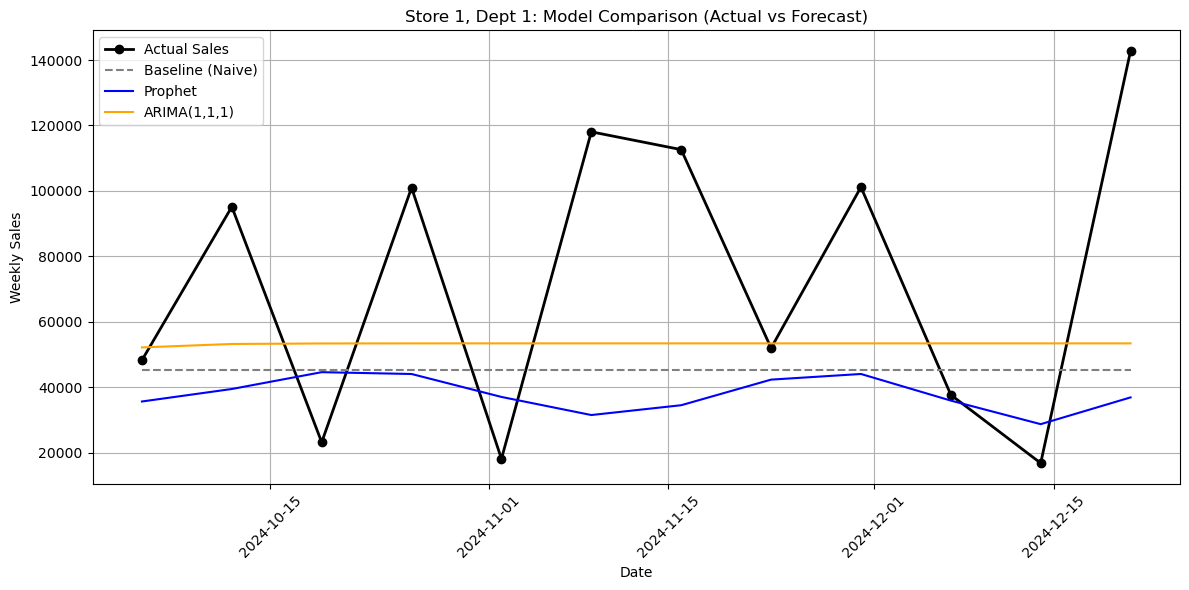

In [5]:
# Create a Summary Comparison Table for Notebook 3
comparison_df = pd.DataFrame({
    'Model': ['Baseline (Naive)', 'Prophet', 'ARIMA(1,1,1)'],
    'MAE': [baseline_mae, prophet_mae, arima_mae],
    'RMSE': [baseline_rmse, prophet_rmse, arima_rmse]
})

print("--- Model Performance Comparison (Test Set) ---")
display(comparison_df.sort_values(by='RMSE'))

# Plotting Actual vs Predictions
plt.figure(figsize=(12, 6))
plt.plot(test_df['date'], test_df['weekly_sales'], label='Actual Sales', color='black', marker='o', linewidth=2)
plt.plot(test_df['date'], baseline_preds, label='Baseline (Naive)', linestyle='--', color='gray')
plt.plot(test_df['date'], prophet_preds, label='Prophet', linestyle='-', color='blue')
plt.plot(test_df['date'], arima_preds, label='ARIMA(1,1,1)', linestyle='-', color='orange')

plt.title(f'Store {store_id}, Dept {dept_id}: Model Comparison (Actual vs Forecast)')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# Train and Evaluate SARIMA Model
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    # Fitting SARIMA model: order=(1,1,1), seasonal_order=(1,1,1,52) for weekly seasonality
    sarima_model = SARIMAX(train_sales, 
                           order=(1, 1, 1), 
                           seasonal_order=(1, 1, 1, 52),
                           enforce_stationarity=False, 
                           enforce_invertibility=False)
    sarima_fitted = sarima_model.fit(disp=False)
    
    # Forecast
    sarima_preds = sarima_fitted.forecast(steps=len(test_sales))
    
    # Evaluate SARIMA
    sarima_mae = mean_absolute_error(test_sales, sarima_preds)
    sarima_rmse = np.sqrt(mean_squared_error(test_sales, sarima_preds))
    
    print(f"--- SARIMA Model ---")
    print(f"SARIMA MAE: {sarima_mae:.2f}")
    print:print(f"SARIMA RMSE: {sarima_rmse:.2f}")
    
    # Update Comparison Table to include SARIMA
    updated_comparison_df = pd.DataFrame({
        'Model': ['Baseline (Naive)', 'Prophet', 'ARIMA(1,1,1)', 'SARIMA'],
        'MAE': [baseline_mae, prophet_mae, arima_mae, sarima_mae],
        'RMSE': [baseline_rmse, prophet_rmse, arima_rmse, sarima_rmse]
    })
    
    print("\n--- Updated Model Performance Comparison ---")
    display(updated_comparison_df.sort_values(by='RMSE'))

except Exception as e:
    print(f"SARIMA execution note: {e}")

--- SARIMA Model ---
SARIMA MAE: 40055.98
SARIMA RMSE: 47795.23

--- Updated Model Performance Comparison ---


,Model,MAE,RMSE
2,"ARIMA(1,1,1)",39448.051453,46284.686110
3,SARIMA,40055.982267,47795.227823
0,Baseline (Naive),41193.712500,50205.851006
1,Prophet,43021.442515,54453.000261
